In [1]:
import os
import seaborn as sns
import matplotlib.pyplot as plt 
import numpy as np 
import pandas as pd 
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [2]:
# Cargar el dataset sin anomalías (del Notebook 01)
df = pd.read_csv("../data/processed/docentes_enoe_sin_anomalias.csv",
   na_values=["\\N", '\ N', " ", "", "NA", "NaN"])
#("../data/processed/docentes_enoe_sin_anomalias.csv",
#   na_values=["\\N", '\ N', " ", "", "NA", "NaN"])
    
    


<>:3: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
<>:3: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
C:\Users\David\AppData\Local\Temp\ipykernel_15304\1002454660.py:3: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
  na_values=["\\N", '\ N', " ", "", "NA", "NaN"])


In [3]:
# Preparar variables econométricas
cols_modelo = ["ingocup", "hrsocup", "eda", "sex", "cs_p13_1", "p3a"]

In [4]:
# Utilizaremos el modelo de ecuacíon salarial Mincer econometrica (usanmos la transformada logaritmica) 

for col in cols_modelo:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Depurar filas con nulos y filtrar salarios y horas positivas
df_model = df.dropna(subset=cols_modelo).copy()
df_model = df_model[(df_model["ingocup"] > 0) & (df_model["hrsocup"] > 0)]

print(f"muestra efectiva valida para la ecuación de Mincer: {len(df_model)} docentes.")

# Variable Dummy de género (1 = Mujer, 0 = Hombre)
df_model["mujer"] = (
    (df_model["sex"] == 2.0) | (df_model["sex"] == 2)
).astype(int)

# Experiencia / Edad cuadrática (retornos decrecientes de Mincer)
df_model["eda2"] = df_model["eda"] ** 2

# Logaritmo natural del ingreso mensual (variable dependiente)
df_model["log_ingocup"] = np.log(df_model["ingocup"])

# Formular y ajustar el modelo minceriano con errores estándar robustos (HC3)
formula_mincer = (
    "log_ingocup ~ mujer + hrsocup + eda + eda2 + "
    "C(cs_p13_1, Treatment(reference=7.0)) + C(p3a)"
)

modelo_mincer = smf.ols(formula_mincer, data=df_model).fit(cov_type="HC3")

# Resumen
print("\n=== RESUMEN DE LA ECUACIÓN SALARIAL DE MINCER ===") 
print(modelo_mincer.summary().tables[1])

muestra efectiva valida para la ecuación de Mincer: 1147 docentes.

=== RESUMEN DE LA ECUACIÓN SALARIAL DE MINCER ===
                                                   coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------
Intercept                                        8.2207      0.189     43.466      0.000       7.850       8.591
C(cs_p13_1, Treatment(reference=7.0))[T.2.0]    -0.3630      0.250     -1.454      0.146      -0.852       0.126
C(cs_p13_1, Treatment(reference=7.0))[T.3.0]    -0.2588      0.174     -1.485      0.138      -0.600       0.083
C(cs_p13_1, Treatment(reference=7.0))[T.4.0]    -0.4745      0.091     -5.243      0.000      -0.652      -0.297
C(cs_p13_1, Treatment(reference=7.0))[T.5.0]     0.0770      0.105      0.732      0.464      -0.129       0.283
C(cs_p13_1, Treatment(reference=7.0))[T.6.0]    -0.4374      0.143     -3.056      0.002   

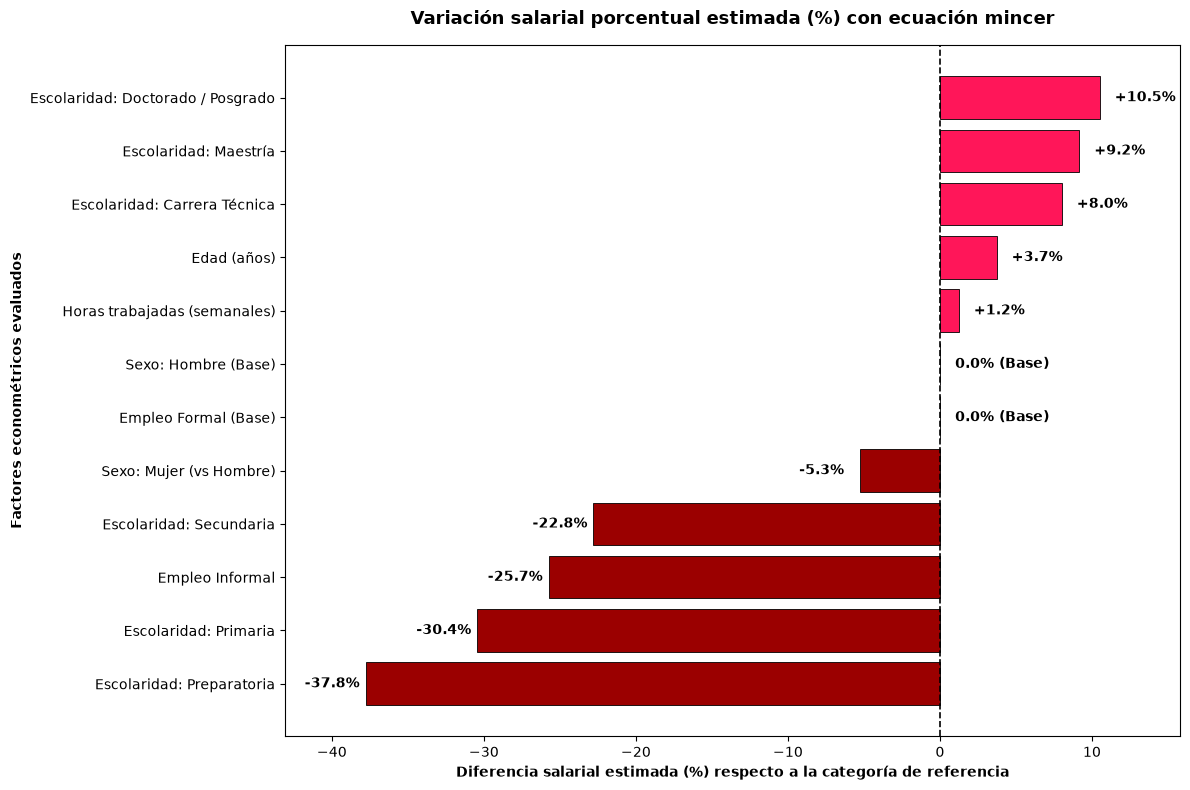

In [17]:
# Diccionario de traducción de las columnas
diccionario_nombres = {
    "hrsocup": "Horas trabajadas (semanales)",
    "eda": "Edad (años)",
    "mujer": "Sexo: Mujer (vs Hombre)",
    "C(p3a)[T.2]": "Empleo Informal",
    # Niveles educativos comparados directamente contra Licenciatura (7.0)
    "C(cs_p13_1, Treatment(reference=7.0))[T.2.0]": "Escolaridad: Primaria",
    "C(cs_p13_1, Treatment(reference=7.0))[T.3.0]": "Escolaridad: Secundaria",
    "C(cs_p13_1, Treatment(reference=7.0))[T.4.0]": "Escolaridad: Preparatoria",
    "C(cs_p13_1, Treatment(reference=7.0))[T.5.0]": "Escolaridad: Carrera Técnica",
    "C(cs_p13_1, Treatment(reference=7.0))[T.8.0]": "Escolaridad: Maestría",
    "C(cs_p13_1, Treatment(reference=7.0))[T.9.0]": "Escolaridad: Doctorado / Posgrado",
}

# Lista de variables que NO quieres mostrar en la gráfica
variables_a_excluir = ["C(cs_p13_1, Treatment(reference=7.0))[T.0.0]", "eda2",
                        "C(cs_p13_1, Treatment(reference=7.0))[T.6.0]"]

# Extraer coeficientes excluyendo el intercepto y las variables anteriores
params = modelo_mincer.params.drop(["Intercept"] + variables_a_excluir, errors="ignore")

df_mincer_coef = pd.DataFrame(
    {
        "Variable_Cod": params.index,
        "Cambio_Porcentual": (np.exp(params.values) - 1) * 100,
        "Es_Base": False,
    }
)

df_mincer_coef["Variable_Label"] = (
    df_mincer_coef["Variable_Cod"]
    .map(diccionario_nombres)
    .fillna(df_mincer_coef["Variable_Cod"])
)

# Incluir explícitamente las categorías base (0.0%)
filas_base = pd.DataFrame(
    [
        {
            "Variable_Label": "Sexo: Hombre (Base)",
            "Cambio_Porcentual": 0.0,
            "Es_Base":True,
        },
        {
            "Variable_Label": "Empleo Formal (Base)",
            "Cambio_Porcentual": 0.0,
            "Es_Base":True,
        }
    ]
)

df_grafica = pd.concat([df_mincer_coef, filas_base], ignore_index=True)
df_grafica = df_grafica.sort_values(by="Cambio_Porcentual", ascending=True)

colores = []
for _, row in df_grafica.iterrows():
    if row["Es_Base"]:
        colores.append("#7f7f7f")
    elif row["Cambio_Porcentual"] >= 0:
        colores.append("#ff1659")
    else:
        colores.append("#9b0000")

os.makedirs("../outputs/figures", exist_ok=True)
plt.figure(figsize=(12, 8))

bars = plt.barh(
    df_grafica["Variable_Label"],
    df_grafica["Cambio_Porcentual"],
    color=colores,
    edgecolor="black",
    linewidth=0.6,
)

plt.axvline(0, color="black", linestyle="--", linewidth=1.2)

for bar in bars:
    width = bar.get_width()
    offset = 1.0 if width >= 0 else -4.0
    text_val = "0.0% (Base)" if width == 0 else f"{width:+.1f}%"
    plt.text(
        width + offset,
        bar.get_y() + bar.get_height() / 2,
        text_val,
        va="center",
        fontsize=10.0,
        fontweight="bold",
        color="black",
    )

max_val = max(abs(df_grafica["Cambio_Porcentual"]))
margin = max_val * 0.14  # Ajusta el margen según tus necesidades
min_x = df_grafica["Cambio_Porcentual"].min()
max_x = df_grafica["Cambio_Porcentual"].max()
plt.xlim(min(min_x -margin, -margin), max(max_x + margin, margin))

plt.title(
    "Variación salarial porcentual estimada (%) con ecuación mincer",
    fontsize=13,
    fontweight="bold",
    pad=15,
)

plt.xlabel(
    "Diferencia salarial estimada (%) respecto a la categoría de referencia",
    fontweight="bold",
)

plt.ylabel("Factores econométricos evaluados", fontweight="bold")
plt.tight_layout()

plt.savefig("../outputs/figures/mincer_coeficientes_porcentaje.png", dpi=300)
plt.show()

Comparación con grafica de puntos

In [6]:
# Extraemos coeficientes de edad y edad cuadrática del modelo
b_eda = modelo_mincer.params.get("eda", 0)
b_eda2 = modelo_mincer.params.get("eda2", 0)
intercepto = modelo_mincer.params.get("Intercept", 0)

# Promedios de las demás variables para mantener el escenario constante
salario_promedio = df_model["ingocup"].mean()

edades = np.arange(20, 66, 1)

# Calcular el logaritmo del ingreso estimado ajustado por edad y edad^2
# Fijando el resto de variables en su punto base/promedio
log_ingreso_base = (intercepto + b_eda * edades + b_eda2 * (edades**2))

In [7]:
# Convertir de logaritmo a pesos reales ($ MXN)
# Escalamos para que coincida con el nivel del salario promedio
ingreso_estimado_pesos = np.exp(log_ingreso_base)
factor_escala = salario_promedio / np.mean(ingreso_estimado_pesos)
ingreso_estimado_pesos = ingreso_estimado_pesos * factor_escala

# Identificar la edad del pico salarial (donde la derivada es cero)
edad_pico = -b_eda / (2 * b_eda2)
salario_pico = (np.exp(intercepto + b_eda * edad_pico + b_eda2 * (edad_pico**2)))

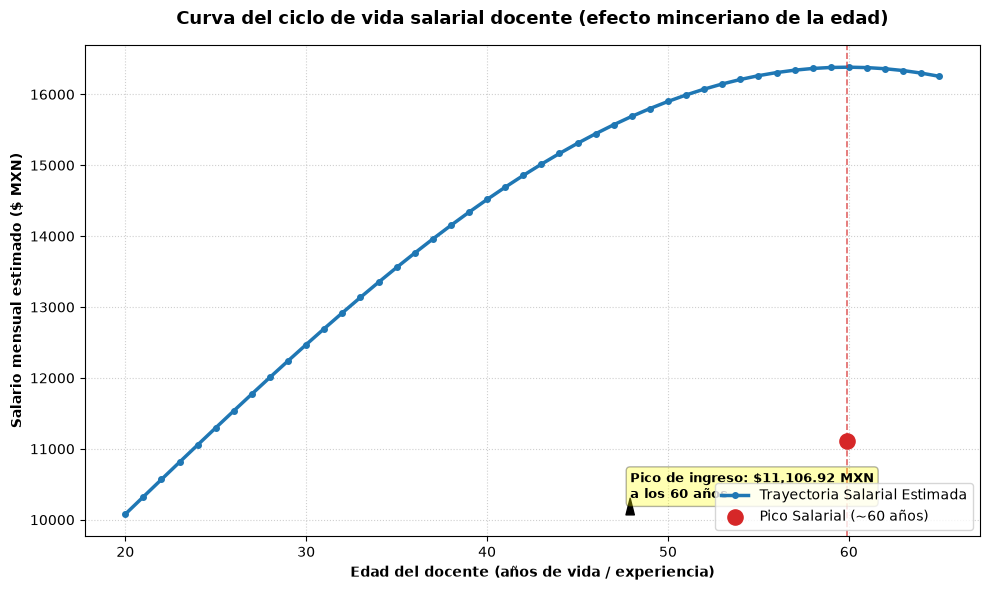

In [8]:
plt.figure(figsize=(10, 6))

plt.plot(
    edades,
    ingreso_estimado_pesos,
    color="#1f77b4",
    linewidth=2.5,
    marker="o",
    markersize=4,
    label="Trayectoria Salarial Estimada",
)

plt.scatter(
    [edad_pico],
    [salario_pico],
    color="#d62728",
    s=120,
    zorder=5,
    label=f"Pico Salarial (~{int(round(edad_pico))} años)",
)

plt.axvline(
    x=edad_pico,
    color="#d62728",
    linestyle="--",
    alpha=0.7,
    linewidth=1.2,
)

plt.annotate(
    f"Pico de ingreso: ${salario_pico:,.2f} MXN\na los {int(round(edad_pico))} años",
    xy=(edad_pico - 12, salario_pico - 800),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
    fontsize=9.5,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.3),
)

plt.title(
    "Curva del ciclo de vida salarial docente (efecto minceriano de la edad)",
    fontsize=13,
    fontweight="bold",
    pad=15,
)

plt.xlabel("Edad del docente (años de vida / experiencia)", fontweight="bold")
plt.ylabel("Salario mensual estimado ($ MXN)", fontweight="bold")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig("../outputs/figures/mincer_curva_edad_salario.png", dpi=300)
plt.show()
